# COGS 108 - Playoff EDA

Runs on the cleaned files in `data/02-processed/`. Run the playoff cleaning notebook first.

In [1]:
# Setup: load both cleaned tables from data/02-processed/
import pandas as pd
import matplotlib.pyplot as plt

df_regular_clean = pd.read_csv('data/02-processed/nba_regular_season_cleaned.csv')
df_playoffs_clean = pd.read_csv('data/02-processed/nba_playoffs_cleaned.csv', dtype={'years_in_nba': 'Int64'})
print(df_regular_clean.shape, df_playoffs_clean.shape)

(5254, 25) (1974, 25)


## 7. Playoff EDA

We repeat the regular-season EDA (section 6) on the cleaned playoff table (`df_playoffs_clean`, 1,974 rows), and compare with the regular season where it helps.

* We work on a copy named `po_eda`, and helper variables start with `po_eda_`, so nothing from earlier sections is changed.
* The 24 rows with `suspicious_entry == True` are left out of correlations and trend analysis, as in section 6.
* **Every number used in the findings is printed** by a code cell, not only shown in a chart, so the text can be checked against the output.
* Reminders from 5J that matter here:
  * the `trend_3yr_*` columns are **3-season averages that include the current season**, not trends;
  * playoff averages need **three postseasons in a row**, so only 654 of the 1,974 rows have one;
  * `plus_minus` is on-court plus/minus, not Box Plus/Minus;
  * Luca Vildoza (2021-22) has no `years_in_nba`, so he's left out of the experience charts only.

In [2]:
po_eda = df_playoffs_clean.copy()
po_eda_no_susp = po_eda[~po_eda['suspicious_entry']].copy()
po_eda_reg = df_regular_clean[~df_regular_clean['suspicious_entry']]    # regular season, for comparisons

# The 3-season average columns are named trend_3yr_* (or avg_3yr_* if they were renamed)
po_eda_avg = 'avg_3yr_' if 'avg_3yr_ppg' in po_eda.columns else 'trend_3yr_'

print(f"Playoff EDA rows: {len(po_eda):,}")
print(f"Suspicious rows left out of correlations and trends: {po_eda['suspicious_entry'].sum()}")
print(f"Rows used for correlations: {len(po_eda_no_susp):,}")
print(f"Unique players: {po_eda['player_id'].nunique():,}")

Playoff EDA rows: 1,974
Suspicious rows left out of correlations and trends: 24
Rows used for correlations: 1,950
Unique players: 724


### 7A. Distributions of the performance stats
Same stats as 6A. The last column is the regular-season median for comparison. Remember that the two tables contain different players: only playoff teams, and coaches use shorter rotations.

,Mean,Median,Std Dev,Skewness,RS Median
ppg,9.658,7.750,7.709,0.993,7.710
rpg,3.901,3.250,2.864,1.098,3.280
apg,2.020,1.260,2.072,1.659,1.480
bpg,0.424,0.260,0.480,2.079,0.300
spg,0.653,0.510,0.534,0.998,0.610
mpg,22.120,22.655,11.846,-0.110,20.465
gp,9.524,7.000,5.440,0.996,57.000
ts_pct,0.539,0.550,0.128,-0.662,0.556
plus_minus,-1.272,-0.670,5.042,-0.720,-0.380


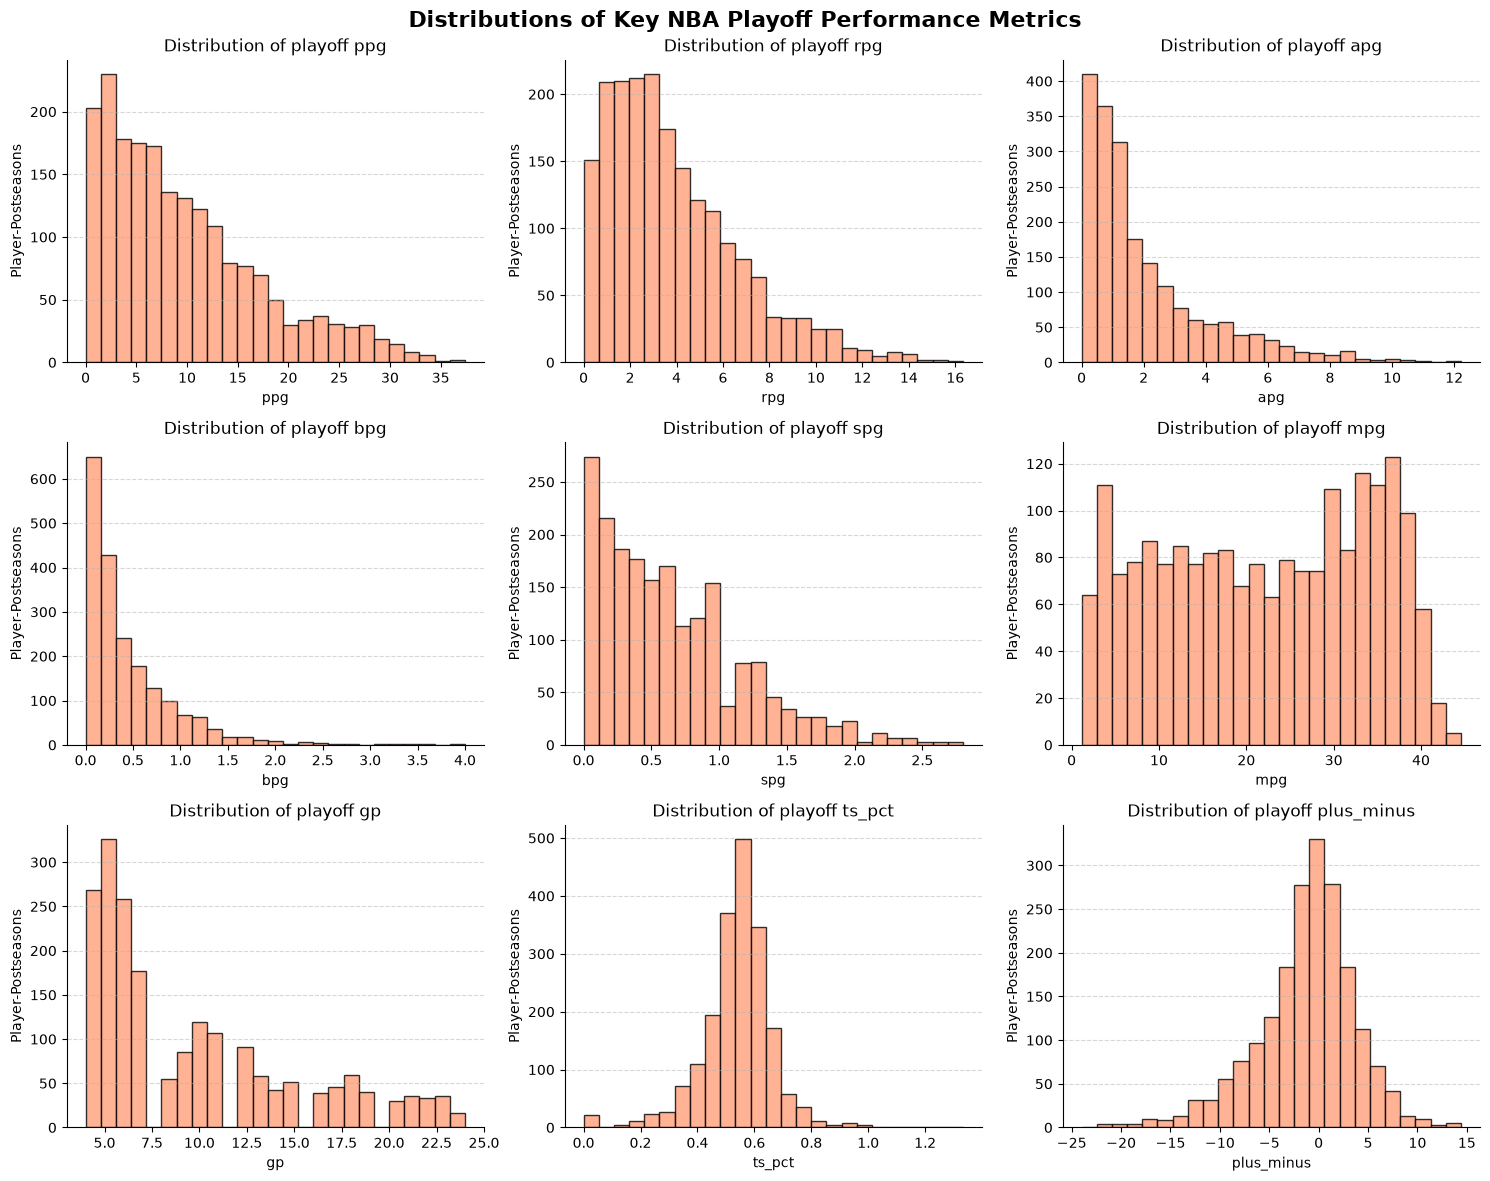

In [3]:
po_eda_stat_cols = ['ppg', 'rpg', 'apg', 'bpg', 'spg', 'mpg', 'gp', 'ts_pct', 'plus_minus']

po_eda_summary = pd.DataFrame({
    'Mean': po_eda[po_eda_stat_cols].mean(),
    'Median': po_eda[po_eda_stat_cols].median(),
    'Std Dev': po_eda[po_eda_stat_cols].std(),
    'Skewness': po_eda[po_eda_stat_cols].skew(),
    'RS Median': df_regular_clean[po_eda_stat_cols].median(),
})
display(po_eda_summary.round(3))

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()
for i, col in enumerate(po_eda_stat_cols):
    axes[i].hist(po_eda[col], bins=25, color='lightsalmon', edgecolor='black', alpha=0.8)
    axes[i].set_title(f'Distribution of playoff {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Player-Postseasons')
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    axes[i].yaxis.grid(True, linestyle='--', alpha=0.5)
plt.suptitle('Distributions of Key NBA Playoff Performance Metrics', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### What we found

* **Right-skewed stats:** `bpg` (skew 2.08), `apg` (1.66), `rpg` (1.10), `spg` (1.00) and `ppg` (0.99) are right-skewed, as in the regular season: most players have low numbers and a few stars have very high ones. For example, `ppg` has a mean of 9.66 and a median of 7.75.
* **Games played is right-skewed too (skew 1.00):** the median is 7 games and the mean 9.52. Most teams go out in the first round or two, so only the teams that go deep play many games. In the regular season, by contrast, `gp` is mostly set by role and health.
* **Close to symmetric:** `mpg` (skew −0.11) has a median of 22.655, compared with 20.465 in the regular season, because coaches shorten their rotations and the remaining players play more.
* **True shooting:** the median is 55.0% (regular season 55.6%), and the spread is much wider: a standard deviation of 0.128, compared with 0.069 in 6A. Playoff samples are only a few games, so a hot or cold week moves a player's TS% a lot.
* **Plus/minus:** mean −1.27, median −0.67, with a tail on the negative side (skew −0.72). Players on teams that are swept or blown out get large negative values.
* **Typical scoring is about the same as the regular season** (median 7.75 vs 7.71), but these are different groups of players. Section 5I compares the same players.

### 7B. Age and experience
Same charts as 6B, with the values behind each line chart printed. The `rows` column shows how many player-postseasons each point is based on, because some playoff groups are small.

Rows with missing years_in_nba (left out of the experience charts): 1
Age quartiles: 25% = 24.0, median = 27.0, 75% = 30.0
years_in_nba: most common = 3, median = 6.0
Regular season for comparison: median age = 26.0, median years_in_nba = 5.0
Share of rows with estimated years_in_nba: 14.5% (regular season: 19.1%)


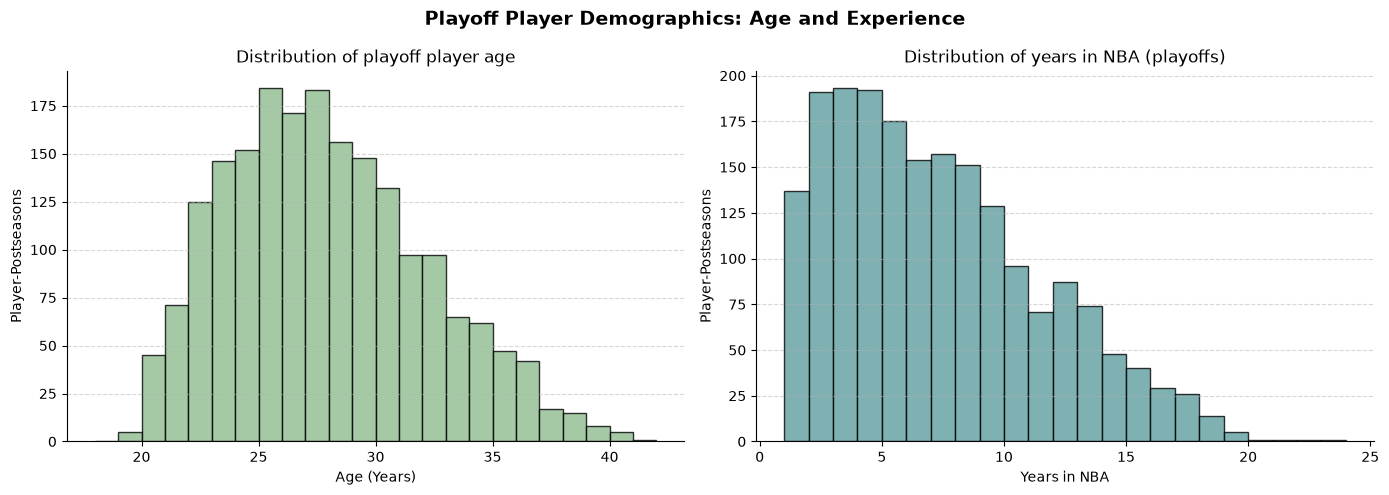


--- Median ppg and mpg by years in NBA ---


,median_ppg,median_mpg,rows
exp_group,,,
1,3.21,10.20,137
2,4.80,14.59,191
3,6.75,19.64,193
4,8.31,22.56,192
5,8.72,24.32,175
6,8.74,23.46,154
7,10.06,26.95,157
8,10.00,26.95,151
9,11.76,29.79,129


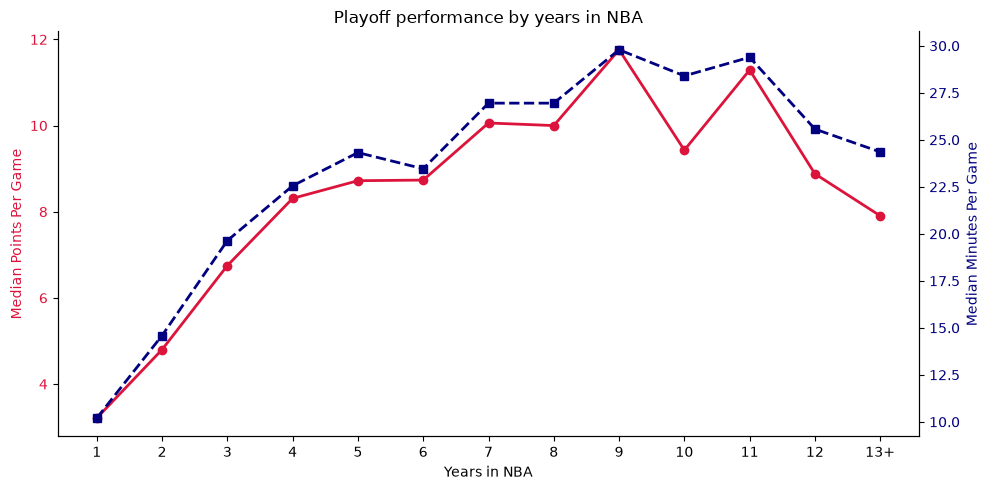


--- Median ppg by age group ---


,median_ppg,rows
age_group,,
21 and under,5.00,121
22,6.00,125
23,7.09,146
24,7.38,152
25,7.49,184
26,8.60,171
27,9.14,183
28,9.55,156
29,8.93,148


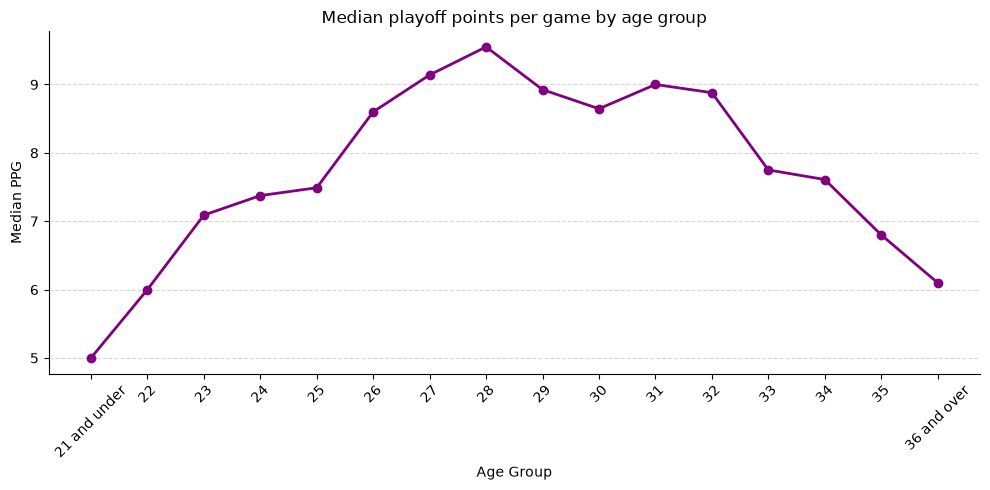

In [4]:
po_eda_years = po_eda['years_in_nba'].dropna()
print(f"Rows with missing years_in_nba (left out of the experience charts): {po_eda['years_in_nba'].isna().sum()}")
print(f"Age quartiles: 25% = {po_eda['age'].quantile(0.25)}, median = {po_eda['age'].median()}, 75% = {po_eda['age'].quantile(0.75)}")
print(f"years_in_nba: most common = {po_eda_years.mode()[0]}, median = {po_eda_years.median()}")
print(f"Regular season for comparison: median age = {df_regular_clean['age'].median()}, "
      f"median years_in_nba = {df_regular_clean['years_in_nba'].median()}")
print(f"Share of rows with estimated years_in_nba: {po_eda['years_in_nba_estimated'].mean():.1%} "
      f"(regular season: {df_regular_clean['years_in_nba_estimated'].mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(po_eda['age'], bins=range(18, 43), color='darkseagreen', edgecolor='black', alpha=0.8)
axes[0].set_title('Distribution of playoff player age')
axes[0].set_xlabel('Age (Years)')
axes[0].set_ylabel('Player-Postseasons')
axes[1].hist(po_eda_years, bins=range(1, int(po_eda_years.max()) + 2), color='cadetblue', edgecolor='black', alpha=0.8)
axes[1].set_title('Distribution of years in NBA (playoffs)')
axes[1].set_xlabel('Years in NBA')
axes[1].set_ylabel('Player-Postseasons')
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.suptitle('Playoff Player Demographics: Age and Experience', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Median ppg and mpg by years in NBA (13+ grouped), rows with a known years_in_nba only
po_eda_exp = po_eda.dropna(subset=['years_in_nba']).copy()
po_eda_exp['exp_group'] = po_eda_exp['years_in_nba'].apply(lambda x: '13+' if x >= 13 else str(int(x)))
po_eda_exp_order = [str(i) for i in range(1, 13)] + ['13+']
po_eda_exp_grouped = (po_eda_exp.groupby('exp_group')
                      .agg(median_ppg=('ppg', 'median'), median_mpg=('mpg', 'median'), rows=('ppg', 'size'))
                      .reindex(po_eda_exp_order))
po_eda_exp_grouped['rows'] = po_eda_exp_grouped['rows'].astype('Int64')
print("\n--- Median ppg and mpg by years in NBA ---")
display(po_eda_exp_grouped.round(2))

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlabel('Years in NBA')
ax1.set_ylabel('Median Points Per Game', color='crimson')
ax1.plot(po_eda_exp_grouped.index, po_eda_exp_grouped['median_ppg'], marker='o', color='crimson', linewidth=2)
ax1.tick_params(axis='y', labelcolor='crimson')
ax1.spines['top'].set_visible(False)
ax2 = ax1.twinx()
ax2.set_ylabel('Median Minutes Per Game', color='navy')
ax2.plot(po_eda_exp_grouped.index, po_eda_exp_grouped['median_mpg'], marker='s', linestyle='--', color='navy', linewidth=2)
ax2.tick_params(axis='y', labelcolor='navy')
ax2.spines['top'].set_visible(False)
plt.title('Playoff performance by years in NBA')
plt.tight_layout()
plt.show()

# Median ppg by age group (same groups as 6B)
def po_eda_age_group(a):
    if a <= 21:
        return '21 and under'
    elif a >= 36:
        return '36 and over'
    return str(int(a))

po_eda['age_group'] = po_eda['age'].apply(po_eda_age_group)
po_eda_age_order = ['21 and under'] + [str(i) for i in range(22, 36)] + ['36 and over']
po_eda_age_grouped = (po_eda.groupby('age_group')
                      .agg(median_ppg=('ppg', 'median'), rows=('ppg', 'size'))
                      .reindex(po_eda_age_order))
po_eda_age_grouped['rows'] = po_eda_age_grouped['rows'].astype('Int64')
print("\n--- Median ppg by age group ---")
display(po_eda_age_grouped.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(po_eda_age_grouped.index, po_eda_age_grouped['median_ppg'], marker='o', color='purple', linewidth=2)
ax.set_title('Median playoff points per game by age group')
ax.set_xlabel('Age Group')
ax.set_ylabel('Median PPG')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### What we found

* **Older and more experienced than the regular season:** the middle half of playoff player-postseasons are between 24 and 30 years old (median 27, compared with 26 in the regular season). The median `years_in_nba` is 6 (regular season 5), and the most common value is 3.
* **Experience:** median playoff `ppg` rises from 3.21 in a player's first year to a peak of 11.76 in year 9, then stays between 7.90 and 11.29 for years 10 to 13+. Median `mpg` follows the same shape: 10.20 in year 1, 29.79 in year 9, 24.36 for 13+. As in 6B, part of this rise is survivor bias, because players who stay in the league longer are usually the better ones.
* **Age:** median `ppg` rises from 5.00 for players 21 and under to a peak of 9.55 at age 28. It stays between 8.60 and 9.55 from 26 to 32, then falls to 6.10 for players 36 and over (88 rows).
* **Estimated years:** 14.5% of playoff rows have `years_in_nba_estimated == True`, compared with 19.1% in the regular season. These are undrafted players, whose years are counted from their first regular season in the database. The database's player stats go back to 1997 (see its `metadata` table), so for these players the count is accurate. The bigger error is in the other direction (see 5J): drafted players who joined the league years later are overcounted.
* **Missing value:** 1 row (Luca Vildoza, 2021-22) has no `years_in_nba`, so it's left out of the experience chart only.

### 7C. Playing time
Same minute groups as 6C. The correlation leaves out the suspicious rows.

,count,median_ppg,median_ts_pct,median_plus_minus
mpg_bin,,,,
0-10,419,1.57,0.500,-0.500
10-20,455,4.75,0.543,-0.670
20-30,444,9.17,0.556,-0.955
30+,656,16.87,0.563,-0.795


Correlation between mpg and ppg (playoffs, without suspicious rows): 0.8613
Same correlation in the regular season: 0.8752
Scoring outliers: 43, lowest mpg among them: 34.13, fewest games among them: 4


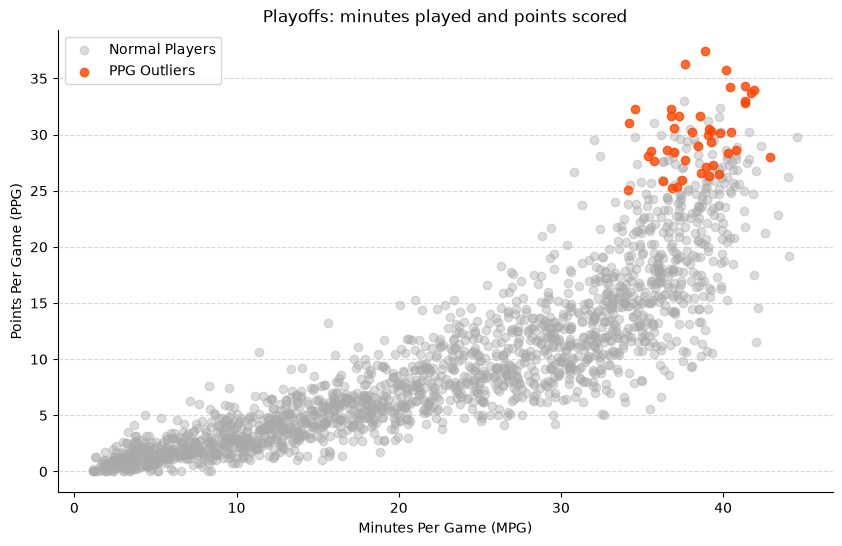

In [5]:
def po_eda_bin_mpg(m):
    if m < 10:
        return '0-10'
    elif m < 20:
        return '10-20'
    elif m < 30:
        return '20-30'
    return '30+'

po_eda['mpg_bin'] = po_eda['mpg'].apply(po_eda_bin_mpg)
po_eda_mpg_grouped = po_eda.groupby('mpg_bin').agg(
    count=('ppg', 'count'),
    median_ppg=('ppg', 'median'),
    median_ts_pct=('ts_pct', 'median'),
    median_plus_minus=('plus_minus', 'median'),
).reindex(['0-10', '10-20', '20-30', '30+'])
display(po_eda_mpg_grouped.round(3))

po_eda_corr_mpg_ppg = po_eda_no_susp['mpg'].corr(po_eda_no_susp['ppg'])
po_eda_reg_corr_mpg_ppg = po_eda_reg['mpg'].corr(po_eda_reg['ppg'])
print(f"Correlation between mpg and ppg (playoffs, without suspicious rows): {po_eda_corr_mpg_ppg:.4f}")
print(f"Same correlation in the regular season: {po_eda_reg_corr_mpg_ppg:.4f}")

po_eda_outliers = po_eda[po_eda['ppg_outlier']]
print(f"Scoring outliers: {len(po_eda_outliers)}, lowest mpg among them: {po_eda_outliers['mpg'].min():.2f}, "
      f"fewest games among them: {po_eda_outliers['gp'].min():.0f}")

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(po_eda[~po_eda['ppg_outlier']]['mpg'], po_eda[~po_eda['ppg_outlier']]['ppg'],
           alpha=0.4, color='darkgray', label='Normal Players')
ax.scatter(po_eda_outliers['mpg'], po_eda_outliers['ppg'], alpha=0.8, color='orangered', label='PPG Outliers')
ax.set_title('Playoffs: minutes played and points scored')
ax.set_xlabel('Minutes Per Game (MPG)')
ax.set_ylabel('Points Per Game (PPG)')
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.show()

### What we found

* **More players play big minutes:** 656 of 1,974 playoff rows (about a third) are in the 30+ minute group, compared with 1,005 of 5,254 (about a fifth) in 6C. This matches 7A: coaches shorten their rotations.
* **Bigger roles score more and shoot better:** from 0-10 minutes to 30+, median `ppg` goes from 1.57 to 16.87 and median `ts_pct` from 50.0% to 56.3%.
* **Plus/minus is negative in every minute group:** the medians are −0.50, −0.67, −0.955 and −0.795. In the regular season the 30+ group was positive (+1.64 in 6C). In the playoffs, every team plays good teams, and half of all games are losses.
* **Minutes and points still go together:** the correlation between `mpg` and `ppg` is 0.861, slightly below the regular season's 0.875 (without suspicious rows).
* **Scoring outliers:** all 43 playoff scoring outliers play at least 34.13 minutes per game, and the fewest games among them is 4. So the `gp >= 4` filter removed the 1- to 3-game outliers found in 5D.

### 7D. Relationships between variables
Correlation heatmap as in 6D, without the suspicious rows. The pair table lists each pair of variables **once**, with the regular-season correlation next to it.

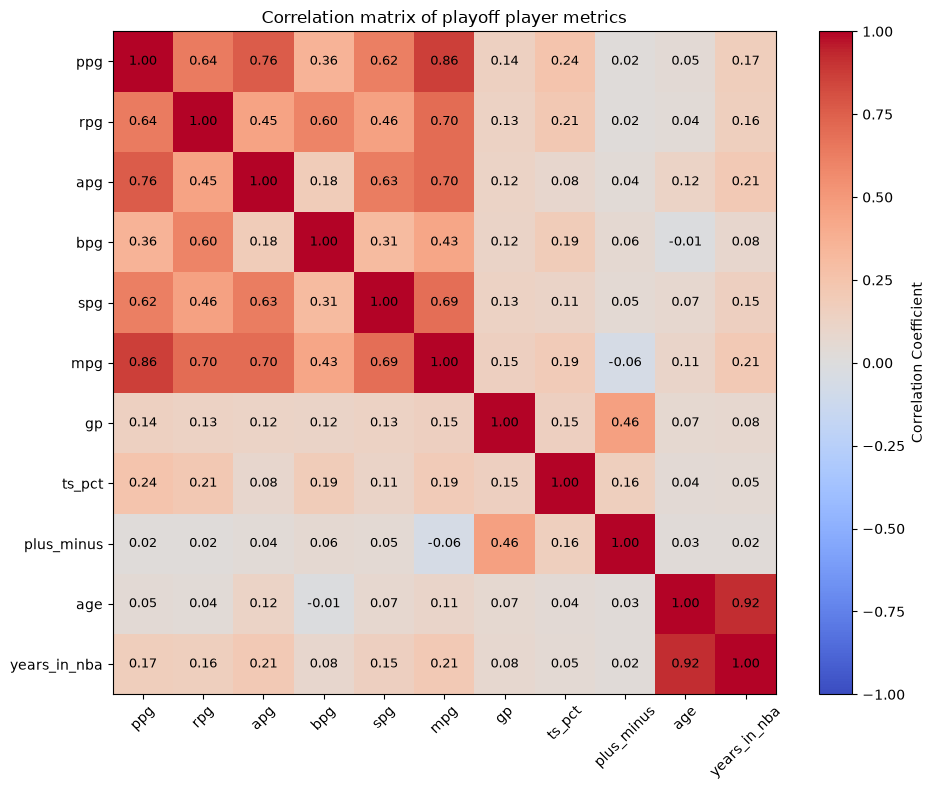

--- Top 5 strongest playoff correlation pairs ---


,var_1,var_2,playoff_corr,regular_season_corr,difference
0,age,years_in_nba,0.918,0.908,0.010
1,ppg,mpg,0.861,0.875,-0.014
2,ppg,apg,0.758,0.714,0.044
3,rpg,mpg,0.701,0.639,0.062
4,apg,mpg,0.698,0.690,0.008


--- 3 pairs that changed most from the regular season ---


,var_1,var_2,playoff_corr,regular_season_corr,difference
0,mpg,gp,0.154,0.598,-0.444
1,ppg,gp,0.141,0.456,-0.315
2,spg,gp,0.129,0.413,-0.284


Correlation between ppg and plus_minus: playoffs 0.02, regular season 0.27
Playoff 20+ ppg scorers: 234, with negative plus_minus: 110 (47%)


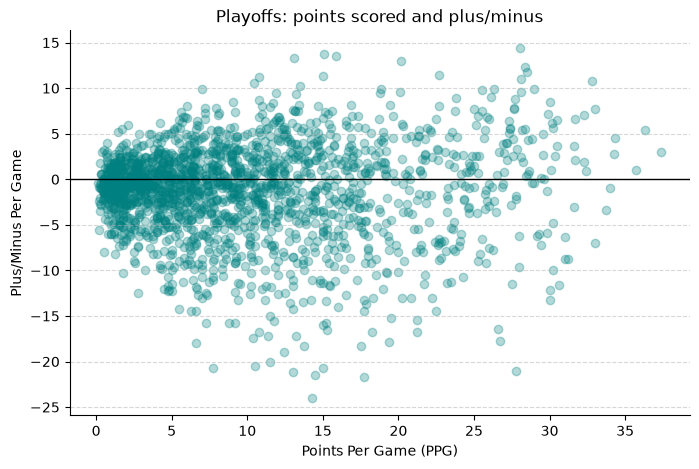

In [6]:
po_eda_corr_cols = ['ppg', 'rpg', 'apg', 'bpg', 'spg', 'mpg', 'gp', 'ts_pct', 'plus_minus', 'age', 'years_in_nba']
po_eda_corr_matrix = po_eda_no_susp[po_eda_corr_cols].corr()
po_eda_reg_corr_matrix = po_eda_reg[po_eda_corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(po_eda_corr_matrix.values, cmap='coolwarm', vmin=-1, vmax=1)
for i in range(len(po_eda_corr_cols)):
    for j in range(len(po_eda_corr_cols)):
        ax.text(j, i, f"{po_eda_corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", color="black", fontsize=9)
ax.set_xticks(range(len(po_eda_corr_cols)))
ax.set_yticks(range(len(po_eda_corr_cols)))
ax.set_xticklabels(po_eda_corr_cols, rotation=45)
ax.set_yticklabels(po_eda_corr_cols)
fig.colorbar(im, ax=ax, label='Correlation Coefficient')
plt.title('Correlation matrix of playoff player metrics')
plt.tight_layout()
plt.show()

# Every pair once (upper triangle), sorted by strength
po_eda_pairs = pd.DataFrame(
    [(a, b, po_eda_corr_matrix.loc[a, b], po_eda_reg_corr_matrix.loc[a, b])
     for i, a in enumerate(po_eda_corr_cols) for b in po_eda_corr_cols[i + 1:]],
    columns=['var_1', 'var_2', 'playoff_corr', 'regular_season_corr'])
po_eda_pairs['difference'] = po_eda_pairs['playoff_corr'] - po_eda_pairs['regular_season_corr']
po_eda_top_pairs = po_eda_pairs.reindex(po_eda_pairs['playoff_corr'].abs().sort_values(ascending=False).index).head(5)
print("--- Top 5 strongest playoff correlation pairs ---")
display(po_eda_top_pairs.round(3).reset_index(drop=True))
print("--- 3 pairs that changed most from the regular season ---")
display(po_eda_pairs.reindex(po_eda_pairs['difference'].abs().sort_values(ascending=False).index).head(3).round(3).reset_index(drop=True))

po_eda_corr_ppg_pm = po_eda_no_susp['ppg'].corr(po_eda_no_susp['plus_minus'])
print(f"Correlation between ppg and plus_minus: playoffs {po_eda_corr_ppg_pm:.2f}, "
      f"regular season {po_eda_reg['ppg'].corr(po_eda_reg['plus_minus']):.2f}")
po_eda_scorers = po_eda_no_susp[po_eda_no_susp['ppg'] >= 20]
print(f"Playoff 20+ ppg scorers: {len(po_eda_scorers)}, with negative plus_minus: "
      f"{(po_eda_scorers['plus_minus'] < 0).sum()} ({(po_eda_scorers['plus_minus'] < 0).mean():.0%})")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(po_eda_no_susp['ppg'], po_eda_no_susp['plus_minus'], alpha=0.3, color='teal')
ax.axhline(0, color='black', linewidth=1)
ax.set_title('Playoffs: points scored and plus/minus')
ax.set_xlabel('Points Per Game (PPG)')
ax.set_ylabel('Plus/Minus Per Game')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.show()

### What we found

* **Strongest pairs:** `age` & `years_in_nba` (0.918), `ppg` & `mpg` (0.861), `ppg` & `apg` (0.758), `rpg` & `mpg` (0.701), `apg` & `mpg` (0.698). These are almost the same as in the regular season; the biggest difference among them is `rpg` & `mpg` (0.701 vs 0.639).
* **Games played changes meaning in the playoffs:** the three pairs that changed most all involve `gp`. The correlation of `gp` with `mpg` drops from 0.598 to 0.154, with `ppg` from 0.456 to 0.141, and with `spg` from 0.413 to 0.129. In the regular season, more games usually means a bigger, steadier role. In the playoffs, the number of games mostly depends on how far the team goes, not on the player.
* **Scoring doesn't predict playoff plus/minus:** the correlation between `ppg` and `plus_minus` is 0.02 in the playoffs, compared with 0.27 in the regular season. Of the 234 player-postseasons with 20+ `ppg`, 110 (47%) have a negative `plus_minus`. In the playoffs a team's top scorers are on the court for most of its losses, so plus/minus reflects the matchup more than the scorer.
* **Collinearity:** as in 6D, `age` and `years_in_nba` carry nearly the same information, and most box-score stats rise with minutes.

### 7E. Playoff changes over time
Season-by-season averages, printed as a table. Note:
* `mean_ts_pct` is the **average of players' TS%**, with every player counted equally. It's not the league's overall playoff TS%, because the table has no shot attempts to weight by.
* The 2020 postseason (2019-20) was played in the Orlando "bubble" with no home crowds.

,rows,mean_ppg,median_ppg,mean_ts_pct,mean_mpg,rs_mean_ts_pct
season,,,,,,
2016,189,8.509,6.750,0.510,21.151,0.530
2017,175,9.646,7.570,0.540,22.203,0.537
2018,176,9.667,8.200,0.535,22.424,0.540
2019,179,9.590,7.730,0.532,22.008,0.544
2020,162,10.832,9.110,0.551,24.168,0.553
2021,192,9.626,7.200,0.547,21.165,0.556
2022,187,9.414,8.000,0.551,21.532,0.552
2023,174,10.080,8.025,0.546,22.652,0.568
2024,170,10.137,7.930,0.533,23.415,0.564


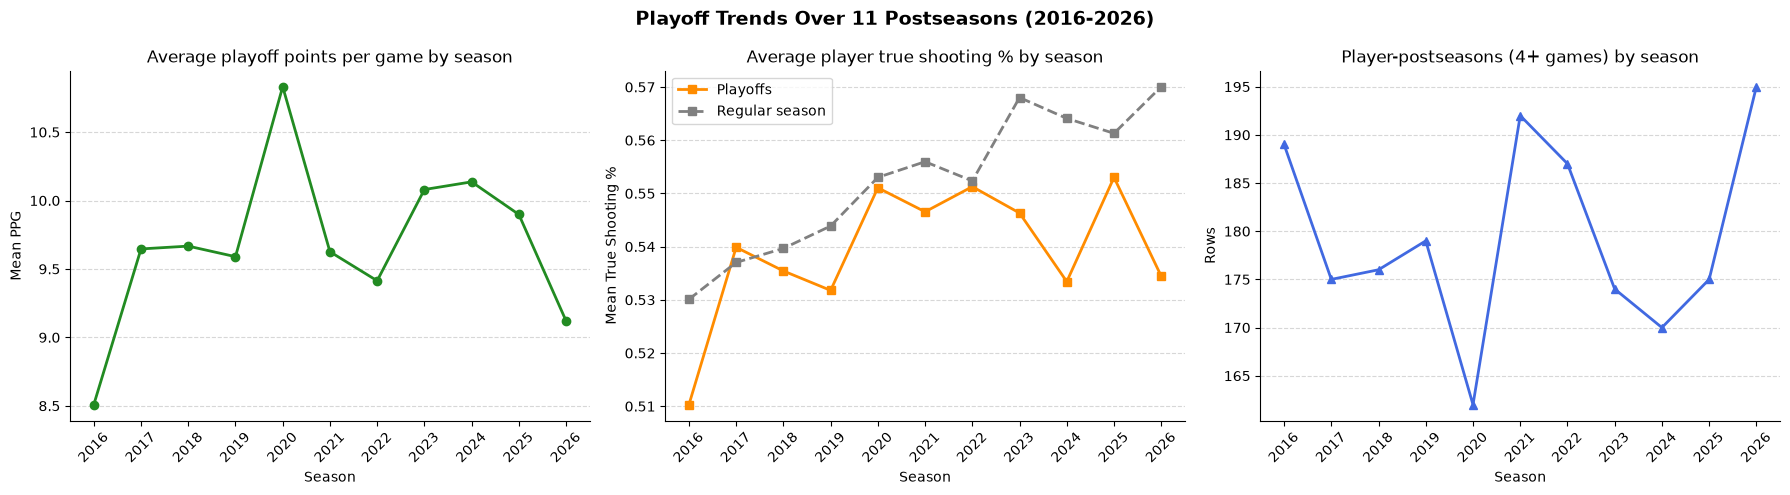

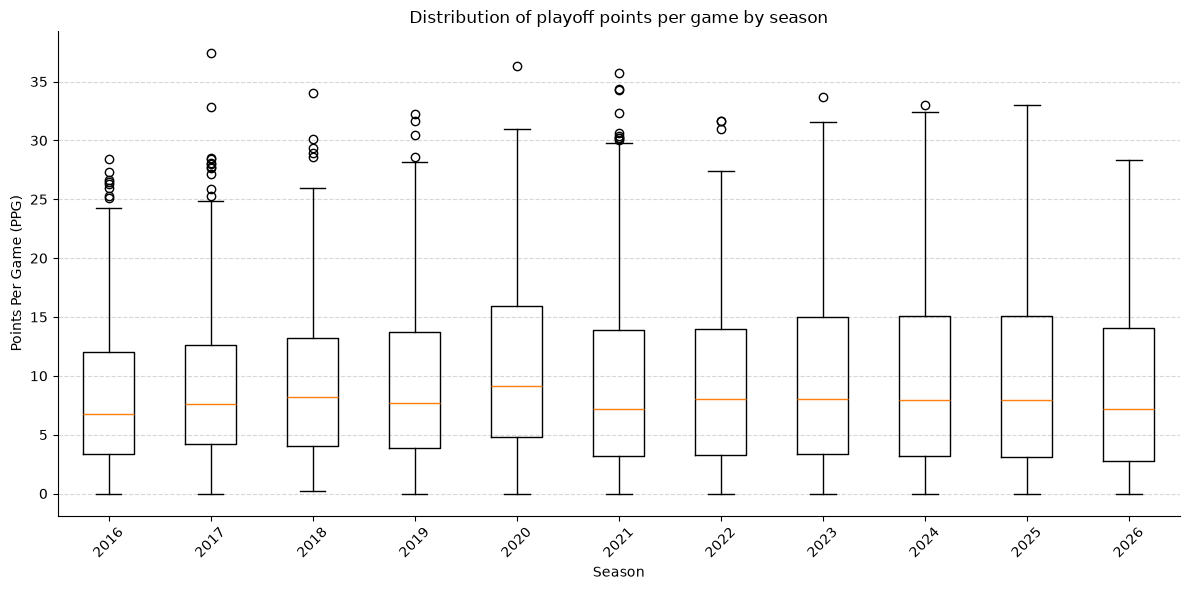

In [7]:
po_eda_season_trends = po_eda.groupby('season').agg(
    rows=('player_id', 'count'),
    mean_ppg=('ppg', 'mean'),
    median_ppg=('ppg', 'median'),
    mean_ts_pct=('ts_pct', 'mean'),
    mean_mpg=('mpg', 'mean'),
).sort_index()
po_eda_season_trends['rs_mean_ts_pct'] = df_regular_clean.groupby('season')['ts_pct'].mean()
display(po_eda_season_trends.round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(po_eda_season_trends.index, po_eda_season_trends['mean_ppg'], marker='o', color='forestgreen', linewidth=2)
axes[0].set_title('Average playoff points per game by season')
axes[0].set_ylabel('Mean PPG')
axes[1].plot(po_eda_season_trends.index, po_eda_season_trends['mean_ts_pct'], marker='s', color='darkorange', linewidth=2, label='Playoffs')
axes[1].plot(po_eda_season_trends.index, po_eda_season_trends['rs_mean_ts_pct'], marker='s', linestyle='--', color='gray', linewidth=2, label='Regular season')
axes[1].set_title('Average player true shooting % by season')
axes[1].set_ylabel('Mean True Shooting %')
axes[1].legend()
axes[2].plot(po_eda_season_trends.index, po_eda_season_trends['rows'], marker='^', color='royalblue', linewidth=2)
axes[2].set_title('Player-postseasons (4+ games) by season')
axes[2].set_ylabel('Rows')
for ax in axes:
    ax.set_xlabel('Season')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)
    ax.set_xticks(po_eda_season_trends.index)
    ax.set_xticklabels([str(x) for x in po_eda_season_trends.index], rotation=45)
plt.suptitle('Playoff Trends Over 11 Postseasons (2016-2026)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

po_eda_seasons = sorted(po_eda['season'].unique())
fig, ax = plt.subplots(figsize=(12, 6))
ax.boxplot([po_eda[po_eda['season'] == s]['ppg'] for s in po_eda_seasons])
ax.set_xticks(range(1, len(po_eda_seasons) + 1))
ax.set_xticklabels([str(s) for s in po_eda_seasons])
ax.set_title('Distribution of playoff points per game by season')
ax.set_xlabel('Season')
ax.set_ylabel('Points Per Game (PPG)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### What we found

* **Player-postseasons per year** range from 162 (2020) to 195 (2026).
* **Playoff shooting is below the regular season almost every year:** average player TS% is lower in the playoffs than in the regular season in 10 of the 11 seasons. The exception is 2017 (54.0% vs 53.7%). The biggest gaps are 2026 (53.4% vs 57.0%) and 2024 (53.3% vs 56.4%). The regular-season column matches 6E (53.0% in 2016 and 57.0% in 2026). Regular-season TS% rises over the period, but playoff TS% doesn't follow it as closely: it ranges from 51.0% (2016) to 55.3% (2025) with no steady direction.
* **Scoring:** average playoff `ppg` is lowest in 2016 (8.51) and highest in 2020 (10.83). In the other years it's between 9.1 and 10.2.
* **2020 stands out:** it has the highest average `ppg` (10.83) and `mpg` (24.17) and the fewest player-postseasons (162). That was the bubble postseason. This table alone can't show whether the bubble caused it.

### 7F. The 3-postseason average columns
**Why this differs from 6F:** the `trend_3yr_*` columns average **this postseason and the two before it**. Subtracting that average from this postseason compares the season partly with itself, so the difference always comes out at exactly **2/3** of the real change. To measure real change, we compare each postseason with the average of the **two previous** postseasons. That average can be worked out exactly from the existing columns:

$$\text{previous-2 average} = \frac{3 \times \text{3-postseason average} - \text{this postseason}}{2}$$

The table below prints both versions side by side to show the 2/3 effect. We use rows with `full_3yr_window == True` and no suspicious entry, as in 6F.

Rows with a full 3-postseason window (no suspicious entries): 653 of 1,974 (33.1%)

--- Change from the average of the 2 previous postseasons ---


,ppg_vs_prev2,mpg_vs_prev2,gp_vs_prev2
count,653.000,653.000,653.000
mean,-0.023,-0.122,0.060
std,4.330,7.275,6.655
min,-13.335,-26.910,-16.995
25%,-2.550,-4.020,-4.500
50%,-0.315,-0.390,-1.005
75%,2.550,3.345,4.500
max,15.660,25.695,18.495


--- The 2/3 effect: spread of each version of the PPG change ---
Std dev of ppg minus previous-2 average: 4.330
Std dev of ppg minus 3-postseason average: 2.886  (ratio 0.667, expected 0.667)

Postseasons at least 3 ppg ABOVE the previous-2 average: 145 (22.2%)
Postseasons at least 3 ppg BELOW the previous-2 average: 144 (22.1%)
(Measured the 6F way, against the 3-postseason average: 87 above, 87 below)


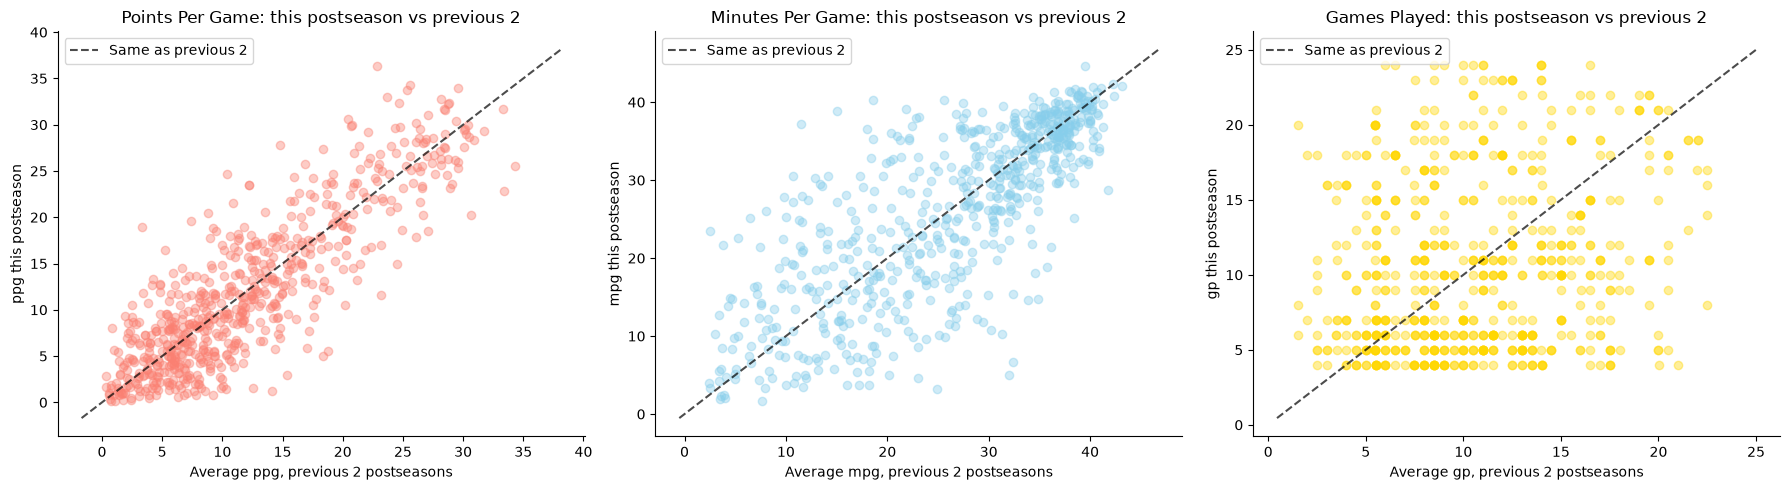


Cleaned playoff rows with no 3-postseason average: 1,320 of 1,974 (66.9%)
--- Share with no 3-postseason average, by years in NBA ---


,rows,pct_missing
exp_bin,,
1-2,328,100.0
3,193,72.5
4-5,367,65.7
6-9,591,59.7
10+,494,52.0
Unknown,1,100.0


In [8]:
po_eda_trend = po_eda_no_susp[po_eda_no_susp['full_3yr_window']].copy()
print(f"Rows with a full 3-postseason window (no suspicious entries): {len(po_eda_trend):,} "
      f"of {len(po_eda):,} ({len(po_eda_trend) / len(po_eda):.1%})")

for stat in ['ppg', 'mpg', 'gp']:
    po_eda_trend[f'prev2_avg_{stat}'] = (3 * po_eda_trend[po_eda_avg + stat] - po_eda_trend[stat]) / 2
    po_eda_trend[f'{stat}_vs_prev2'] = po_eda_trend[stat] - po_eda_trend[f'prev2_avg_{stat}']
    po_eda_trend[f'{stat}_vs_3yr_avg'] = po_eda_trend[stat] - po_eda_trend[po_eda_avg + stat]

po_eda_change_cols = ['ppg_vs_prev2', 'mpg_vs_prev2', 'gp_vs_prev2']
print("\n--- Change from the average of the 2 previous postseasons ---")
display(po_eda_trend[po_eda_change_cols].describe().round(3))

print("--- The 2/3 effect: spread of each version of the PPG change ---")
po_eda_sd_new = po_eda_trend['ppg_vs_prev2'].std()
po_eda_sd_old = po_eda_trend['ppg_vs_3yr_avg'].std()
print(f"Std dev of ppg minus previous-2 average: {po_eda_sd_new:.3f}")
print(f"Std dev of ppg minus 3-postseason average: {po_eda_sd_old:.3f}  (ratio {po_eda_sd_old / po_eda_sd_new:.3f}, expected 0.667)")

po_eda_up3 = (po_eda_trend['ppg_vs_prev2'] >= 3).sum()
po_eda_down3 = (po_eda_trend['ppg_vs_prev2'] <= -3).sum()
print(f"\nPostseasons at least 3 ppg ABOVE the previous-2 average: {po_eda_up3} ({po_eda_up3 / len(po_eda_trend):.1%})")
print(f"Postseasons at least 3 ppg BELOW the previous-2 average: {po_eda_down3} ({po_eda_down3 / len(po_eda_trend):.1%})")
print(f"(Measured the 6F way, against the 3-postseason average: {(po_eda_trend['ppg_vs_3yr_avg'] >= 3).sum()} above, "
      f"{(po_eda_trend['ppg_vs_3yr_avg'] <= -3).sum()} below)")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, stat, name, color in zip(axes, ['ppg', 'mpg', 'gp'],
                                 ['Points Per Game', 'Minutes Per Game', 'Games Played'],
                                 ['salmon', 'skyblue', 'gold']):
    ax.scatter(po_eda_trend[f'prev2_avg_{stat}'], po_eda_trend[stat], alpha=0.4, color=color)
    lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lims, lims, 'k--', alpha=0.7, label='Same as previous 2')
    ax.set_title(f'{name}: this postseason vs previous 2')
    ax.set_xlabel(f'Average {stat}, previous 2 postseasons')
    ax.set_ylabel(f'{stat} this postseason')
    ax.legend()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

# Who has no 3-postseason average? (all cleaned rows, by experience)
def po_eda_exp_bin(y):
    if pd.isna(y):
        return 'Unknown'
    if y <= 2:
        return '1-2'
    if y == 3:
        return '3'
    if y <= 5:
        return '4-5'
    if y <= 9:
        return '6-9'
    return '10+'

po_eda['exp_bin'] = po_eda['years_in_nba'].apply(po_eda_exp_bin)
po_eda_missing = (po_eda.assign(missing_avg=~po_eda['full_3yr_window'])
                  .groupby('exp_bin').agg(rows=('missing_avg', 'size'), pct_missing=('missing_avg', 'mean'))
                  .reindex(['1-2', '3', '4-5', '6-9', '10+', 'Unknown']).dropna(how='all'))
po_eda_missing['rows'] = po_eda_missing['rows'].astype('Int64')
po_eda_missing['pct_missing'] = (po_eda_missing['pct_missing'] * 100).round(1)
print(f"\nCleaned playoff rows with no 3-postseason average: {(~po_eda['full_3yr_window']).sum():,} "
      f"of {len(po_eda):,} ({(~po_eda['full_3yr_window']).mean():.1%})")
print("--- Share with no 3-postseason average, by years in NBA ---")
display(po_eda_missing)

### What we found

* **Rows used:** 653 of the 1,974 playoff rows (33.1%) have a full 3-postseason window and no suspicious entry.
* **The 6F method understates change by a third:** the standard deviation of "this postseason minus the 3-postseason average" is 2.886, exactly 0.667 of the 4.330 we get when comparing with the previous two postseasons. Counting big changes, the 6F way finds 87 postseasons at least 3 `ppg` above and 87 at least 3 below. The corrected way finds 145 (22.2%) above and 144 (22.1%) below. The same 2/3 effect applies to 6F's regular-season results.
* **No overall drift, but a lot of movement:** compared with the previous two postseasons, the average `ppg` change is −0.02 and the median −0.32, but the middle half ranges from −2.55 to +2.55 and the standard deviation is 4.33 points. Playoff scoring changes a lot from one postseason to the next. Minutes (standard deviation 7.275) and games played (6.655) move even more.
* **Missing 3-postseason averages:** 1,320 of the 1,974 cleaned rows (66.9%) have none. That's 100% of players in years 1-2, 72.5% in year 3, 65.7% in years 4-5, 59.7% in years 6-9, and still 52.0% for players with 10+ years. Even veterans are missing half the time, because a playoff average needs **three straight postseasons**, which depends on the team. As explained in 5J, these values are left blank on purpose. Any analysis that uses them has to keep to `full_3yr_window == True`.

### 7G. Playoff regulars vs one-time appearances
Counts how many postseasons (with 4+ games) each player has in 2016-2026. Players are counted by `player_id`, not by name, so two players with the same name aren't merged.

Players with 4+ playoff games at least once: 724
Players with 1-2 postseasons: 419 (57.9%); with 6+ postseasons: 77 (10.6%)
Most postseasons by one player: 11

Players in the cleaned regular-season table: 1,315; never in the cleaned playoff table: 597 (45.4%)
Players in the cleaned playoff table but never in the cleaned regular-season table: 6


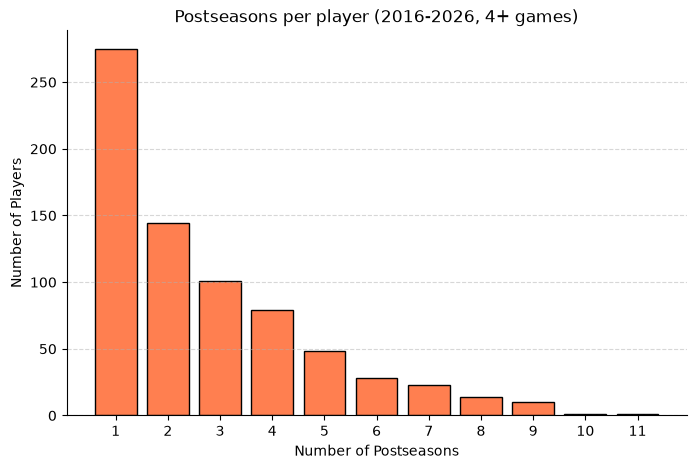

,rows,players,median_ppg,median_mpg,median_age,median_years_in_nba
appearance_group,,,,,,
1-2 postseasons,563,419,3.80,11.86,25.0,4.0
3-5 postseasons,859,228,7.71,21.85,27.0,6.0
6+ postseasons,552,77,13.36,32.77,29.0,8.0


In [9]:
po_eda_counts = po_eda.groupby('player_id').size()
print(f"Players with 4+ playoff games at least once: {len(po_eda_counts):,}")
print(f"Players with 1-2 postseasons: {(po_eda_counts <= 2).sum():,} ({(po_eda_counts <= 2).mean():.1%}); "
      f"with 6+ postseasons: {(po_eda_counts >= 6).sum():,} ({(po_eda_counts >= 6).mean():.1%})")
print(f"Most postseasons by one player: {po_eda_counts.max()}")

po_eda_rs_ids = set(df_regular_clean['player_id'])
po_eda_po_ids = set(po_eda['player_id'])
print(f"\nPlayers in the cleaned regular-season table: {len(po_eda_rs_ids):,}; "
      f"never in the cleaned playoff table: {len(po_eda_rs_ids - po_eda_po_ids):,} "
      f"({len(po_eda_rs_ids - po_eda_po_ids) / len(po_eda_rs_ids):.1%})")
print(f"Players in the cleaned playoff table but never in the cleaned regular-season table: {len(po_eda_po_ids - po_eda_rs_ids)}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(po_eda_counts, bins=range(1, po_eda_counts.max() + 2), align='left', color='coral', edgecolor='black', rwidth=0.8)
ax.set_title('Postseasons per player (2016-2026, 4+ games)')
ax.set_xlabel('Number of Postseasons')
ax.set_ylabel('Number of Players')
ax.set_xticks(range(1, po_eda_counts.max() + 1))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.show()

def po_eda_group(n):
    if n <= 2:
        return '1-2 postseasons'
    if n >= 6:
        return '6+ postseasons'
    return '3-5 postseasons'

po_eda['appearance_group'] = po_eda['player_id'].map(po_eda_counts).apply(po_eda_group)
po_eda_group_table = (po_eda.groupby('appearance_group')
                      .agg(rows=('ppg', 'size'), players=('player_id', 'nunique'),
                           median_ppg=('ppg', 'median'), median_mpg=('mpg', 'median'),
                           median_age=('age', 'median'), median_years_in_nba=('years_in_nba', 'median'))
                      .reindex(['1-2 postseasons', '3-5 postseasons', '6+ postseasons']))
display(po_eda_group_table.round(2))

### What we found

* **Most playoff players appear only once or twice:** 724 players played 4+ games in at least one postseason. 419 of them (57.9%) did it in only 1-2 postseasons, and 77 (10.6%) did it in 6 or more. The most by one player is 11, every postseason in the data.
* **Many players never get there:** of the 1,315 players in the cleaned regular-season table, 597 (45.4%) never appear in the cleaned playoff table. 6 players appear in the playoff table but not the regular-season one, because every regular-season row they have has fewer than 10 games, or they have no regular-season row at all.
* **Playoff regulars have much bigger roles:** players with 6+ postseasons have a median of 13.36 `ppg` and 32.77 `mpg`, compared with 3.80 `ppg` and 11.86 `mpg` for players with 1-2. The 6+ group is also older (median age 29 vs 25) and more experienced (median 8 years vs 4).
* **Be careful:** this counts only postseasons from 2016 to 2026 with 4+ games. A player who debuted in 2024 or retired in 2017 can't have many, whatever his career was. Making the playoffs also depends mostly on the team, so the count reflects which teams a player was on as much as how good he is.

### 7H. Summary of the playoff EDA

* **Playoff rosters are older and lean on fewer players.** The median age is 27 (vs 26) and the median years in the NBA 6 (vs 5). A third of playoff rows are 30+ minute players, compared with a fifth in the regular season.
* **Efficiency drops in the playoffs.** Average player TS% is lower than the regular season in 10 of 11 seasons, and the spread is almost twice as wide (standard deviation 0.128 vs 0.069), partly because playoff samples are small.
* **Plus/minus means something different in the playoffs.** Its median is negative in every minute group and barely related to scoring (correlation 0.02, vs 0.27 in the regular season). It's mostly a result of the matchup.
* **Games played reflects the team, not the player.** Its correlations with minutes and scoring drop by more than half compared with the regular season.
* **Playoff scoring is volatile from year to year.** Compared with the previous two postseasons, 22.2% of players score at least 3 `ppg` more and 22.1% at least 3 less. The 6F method, which compares with an average that includes the current season, understates these changes by a third.
* **Missing 3-postseason averages are a structural limit, not a cleaning problem.** 66.9% of cleaned playoff rows have none, including about half of players with 10+ years, because the value needs three straight postseasons (see 5J). They stay blank, and trend analysis uses `full_3yr_window == True` only.
* **Questions for the next step:**
  1. Do regular-season stats predict how a player's scoring and efficiency change in the playoffs (section 5I)?
  2. Is the drop in playoff TS% larger for some kinds of players, such as high-minute scorers or older players?
  3. For playoff analysis, should we use regular-season averages, which almost every player has, in place of the mostly missing 3-postseason averages?